In [103]:
%pip install -q matplotlib tensorflow numpy tensorflow-probability imageio


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Module 7 Assignment - Improved Digit Generation with VAEs

> Submitted by Phillip Amir Esguerra

> SOURCE MODIFIED: Using keras package directly as I'm using tf 2.19

In [104]:
import tensorflow as tf
import keras
from keras.layers import Input, Dense, Lambda, Flatten, Reshape, Layer
from keras.models import Model
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_probability as tfp
import glob
import imageio

# Load and preprocess MNIST data
(x_train, y_train), (_, _) = keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.
x_train = x_train.reshape((len(x_train), 28, 28, 1))

class Sampling(Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon
    
def build_encoder(input_shape, intermediate_dim, latent_dim):
    encoder_inputs = Input(shape=input_shape)
    x = Flatten()(encoder_inputs)
    x = Dense(intermediate_dim, activation='relu')(x)
    z_mean = Dense(latent_dim, name='z_mean')(x)
    z_log_var = Dense(latent_dim, name='z_log_var')(x)
    z = Sampling()([z_mean, z_log_var])
    encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name='encoder')
    return encoder

def build_decoder(latent_dim, intermediate_dim):
    decoder_inputs = Input(shape=(latent_dim,))
    x = Dense(intermediate_dim, activation='relu')(decoder_inputs)
    x = Dense(784, activation='sigmoid')(x)
    decoder_outputs = Reshape((28, 28, 1))(x)
    decoder = Model(decoder_inputs, decoder_outputs, name='decoder')
    return decoder

class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name='total_loss')
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(name='reconstruction_loss')
        self.kl_loss_tracker = tf.keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            # Encoder output
            z_mean, z_log_var, z = self.encoder(data)
            # Reconstruction
            reconstruction = self.decoder(z)

            # Flatten input and reconstruction for binary crossentropy
            flat_data = tf.reshape(data, (-1, 784))
            flat_reconstruction = tf.reshape(reconstruction, (-1, 784))

            # Reconstruction loss (fixed axis handling)
            reconstruction_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(
                    flat_data,
                    flat_reconstruction
                )
            ) * 784

            # KL divergence loss
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                    axis=1
                )
            )

            # Total loss
            total_loss = reconstruction_loss + kl_loss

        # Compute gradients
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        # Update metrics
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstruction = self.decoder(z)
        return reconstruction


In [ ]:
def generate_digits(decoder, latent_dim, n=10):
    np.random.seed(42069)
    z_sample = np.random.normal(size=(n, latent_dim))
    x_decoded = decoder.predict(z_sample)
    return x_decoded

def plot_latent_space(encoder, indices, epochs, axis):
    x_sample = x_train[indices]
    y_sample = y_train[indices]
    z_mean, _, _ = encoder.predict(x_sample)

    scatter = axis.scatter(z_mean[:, 0], z_mean[:, 1], c=y_sample, cmap='viridis', alpha=0.7, s=3)

    axis.set_title(f"Latent Space after {epochs} Epochs")
    axis.set_xlabel("z[0]")
    axis.set_ylabel("z[1]")
    
    plt.colorbar(scatter, ticks=range(10))
    plt.tight_layout()

def plot_digits(epochs, digits):
    plt.figure(figsize=(10, 2))
    for i in range(10):
        plt.subplot(1, 10, i + 1)
        plt.imshow(digits[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
    plt.tight_layout()
    plt.title(f'Generated Digits after {epochs} Epochs')
    plt.show()

In [106]:
# Network parameters
input_shape = (28, 28, 1)
batch_size = 128
latent_dim = 2
intermediate_dim = 512
epochs = 5

In [107]:
results = []
for epochs in [5, 15, 30, 50, 100]:
    encoder = build_encoder(input_shape, intermediate_dim, latent_dim)
    decoder = build_decoder(latent_dim, intermediate_dim)

    # Create and compile VAE
    print(f"Creating VAE model for {epochs} epochs...")
    vae = VAE(encoder, decoder)
    vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))

    # Train VAE
    print(f"Training VAE for {epochs} epochs...")
    vae.fit(x_train,
            epochs=epochs,
            batch_size=batch_size,
            shuffle=True)

    results.append({
            "epochs": epochs,
            "encoder": encoder,
            "decoder": decoder
        })

Creating VAE model for 5 epochs...
Training VAE for 5 epochs...
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 21.7958 - loss: 379.7675 - reconstruction_loss: 357.9717
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 12.6104 - loss: 212.4292 - reconstruction_loss: 199.8188
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 8.5377 - loss: 196.6395 - reconstruction_loss: 188.1017
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 6.9205 - loss: 190.8093 - reconstruction_loss: 183.8887
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 6.1258 - loss: 187.6174 - reconstruction_loss: 181.4916
Creating VAE model for 15 epochs...
Training VAE for 15 epochs...
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 21.8360 - loss: 380.6772 - reconstruction_loss: 358.8412
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 12.8880 - loss: 210.9496 - reconstruction_loss: 198.0616
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


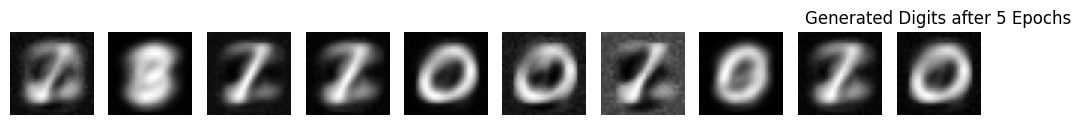

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


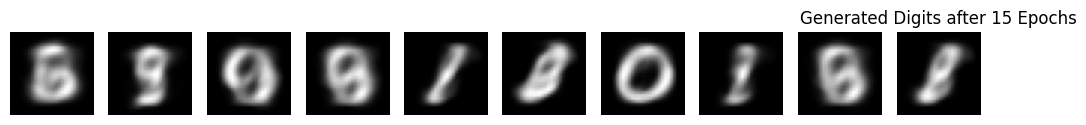

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


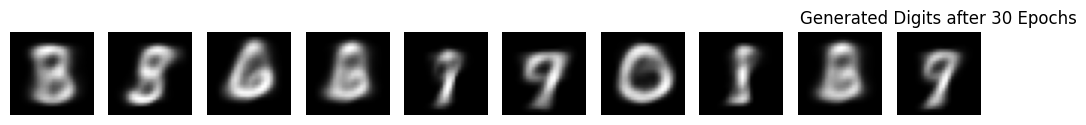

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


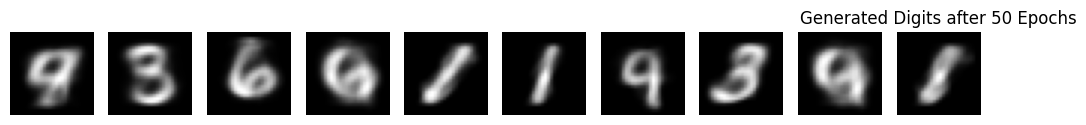

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


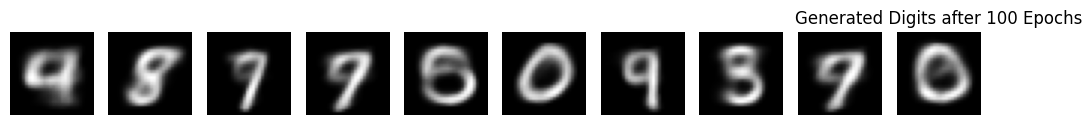

In [112]:
# To visualize the generated digits
for result in results:
    new_digits = generate_digits(result["decoder"], latent_dim, 10)  # Generates 10 new digits
    plot_digits(result["epochs"], new_digits)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 408us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 401us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 408us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 416us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step


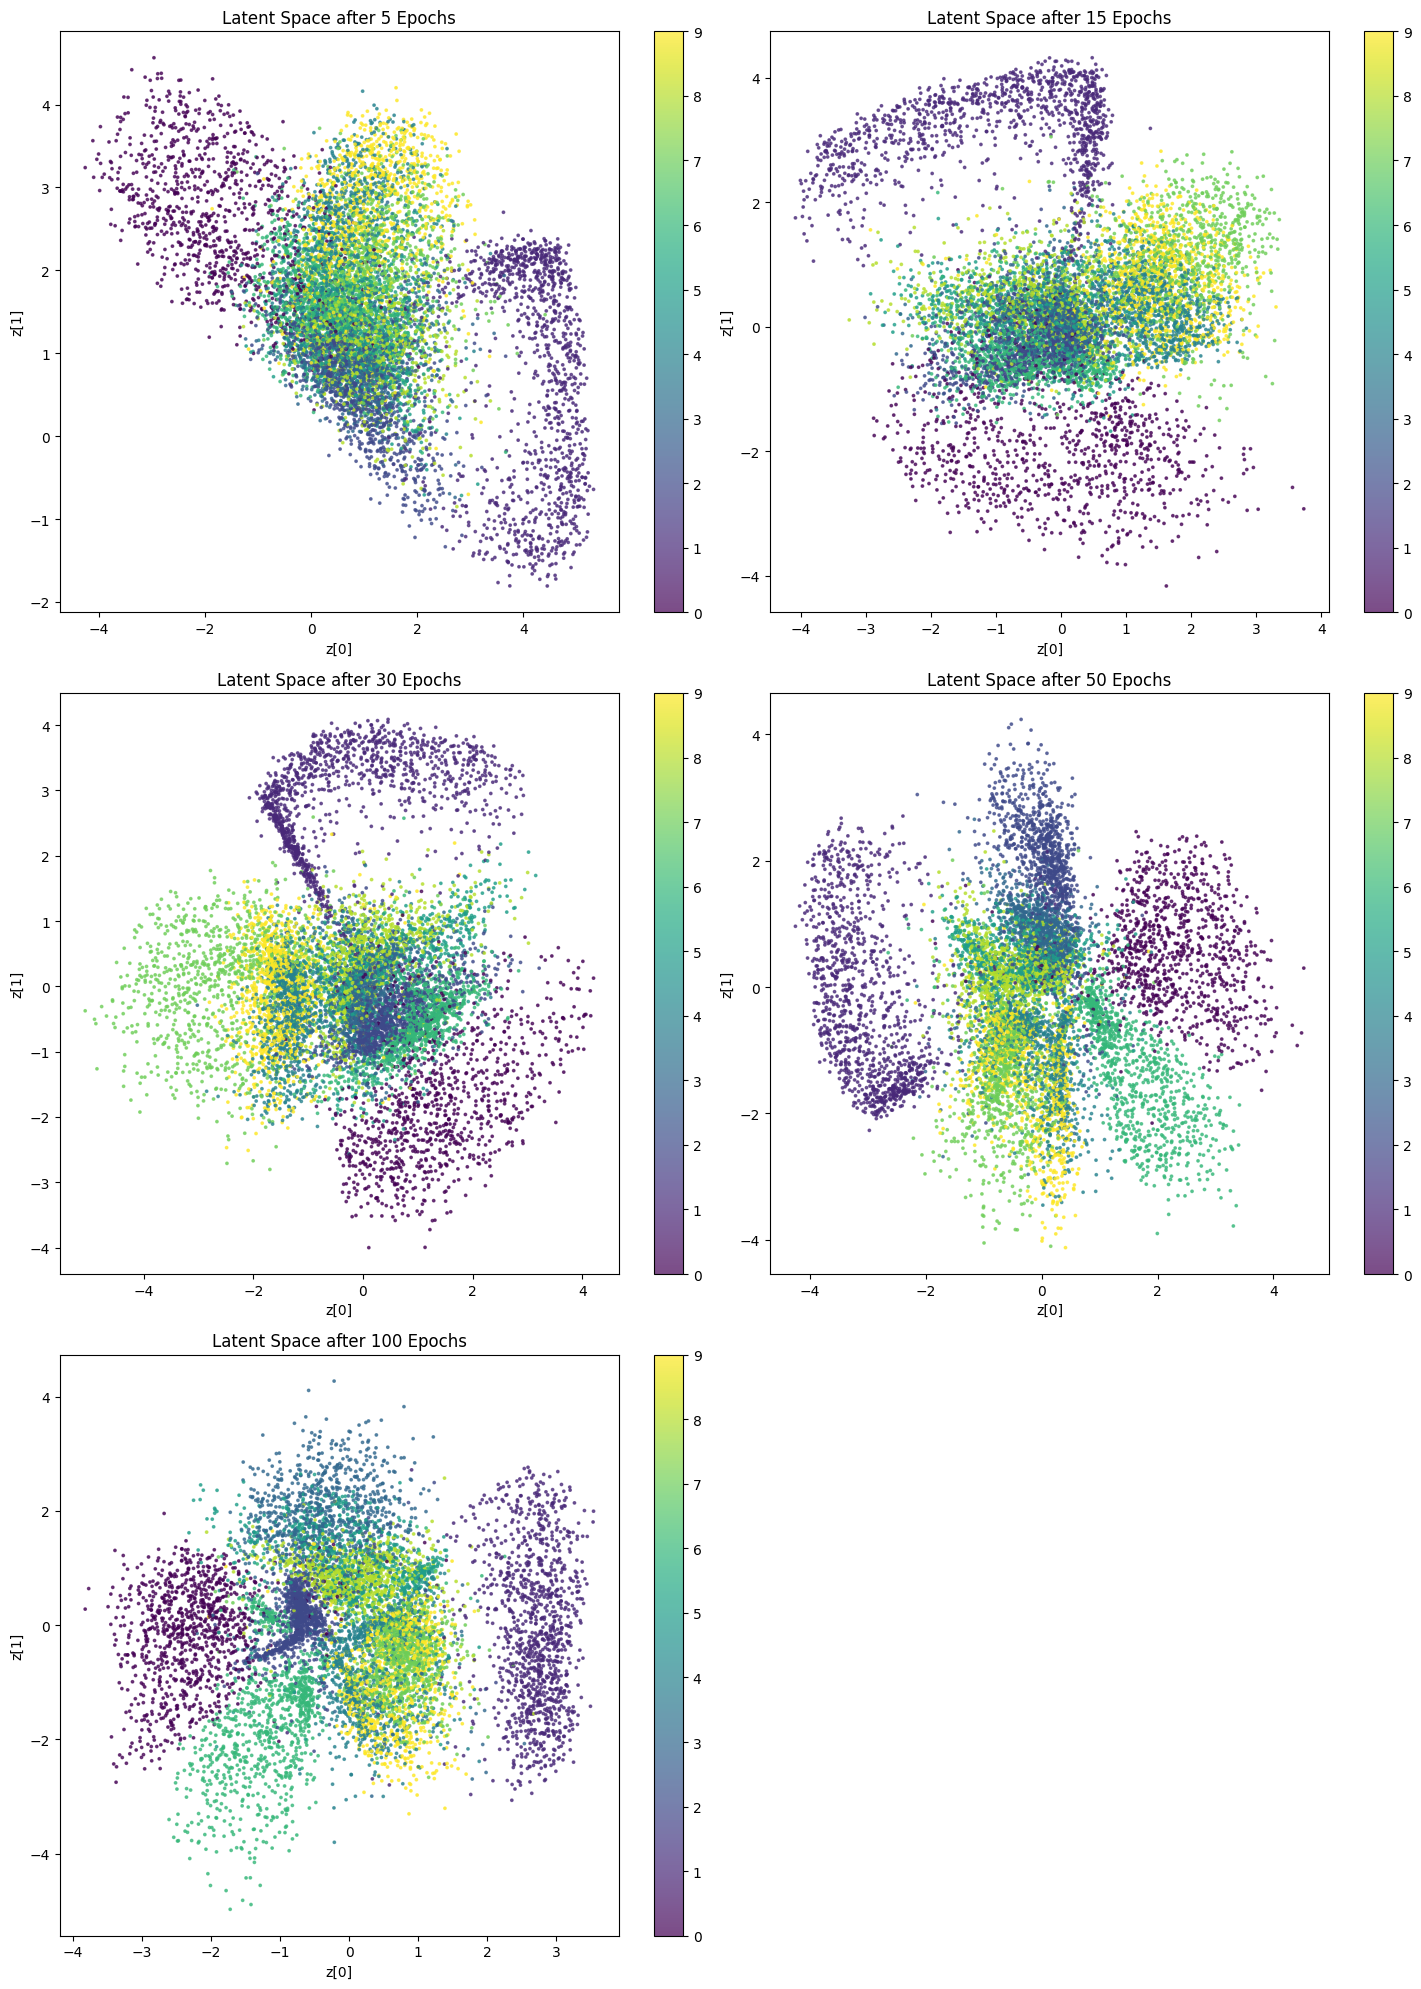

In [109]:
figure, axes = plt.subplots(3,2, figsize=(15, 20))
axes = axes.flatten()

sample_size = 10000
indices = np.random.choice(len(x_train), sample_size, replace=False)

for i, result in enumerate(results):
    plot_latent_space(result["encoder"], indices, result["epochs"], axes[i])

    # save individual plots for animated gif
    extent = axes[i].get_window_extent().transformed(figure.dpi_scale_trans.inverted())
    figure.savefig(f"latent_space_{result['epochs']}.png", bbox_inches=extent, dpi=300)

figure.delaxes(axes[5])

# Latent Space Change Over Epochs

At lower epochs, the latent space has visible overlaps and weak separation between digits. By 15 epocs, we can now distinguish the clusters of sections for each digit. At 30 epochs, a more distinguishable clustering. At later epochs 50 to 100, clusters become more distinct, reflecting a mature and efficient encoding model.

# Generated Digits

At 5 epochs, the generated digits are unrecognizable as numbers and blurry, showing the model's limited generation capabilities. At 15 epochs, we can now notice outlines of what we can say digits but still lack claritiy. By 30 epochs, the digits show a bit of improvement but the ambiguity of digits still remains. At later epochs the digits become more clear of what it might supposed to be. Over epoch's progression, we can notice the models improvement.